In [1]:
from UMAP_utils import *

# Import data

In [2]:
path = "../data/all_MGS.csv"
df = pd.read_csv(path)

In [3]:
# Clean data
df = df.iloc[:, 2:]
df.columns = df.columns.str.strip().str.lower()
df.iloc[:, 1:9] = df.iloc[:, 1:9].apply(pd.to_numeric, errors="coerce")
df = df.dropna()

print("Number of cells is:", df.shape[0])

Number of cells is: 516


In [4]:
df.groupby(["experiment", "sample"]).size()

experiment  sample
20226       MGS1      24
            MGS2      24
            MGS3      30
            MGS4      22
            MGS5      24
            WT        23
140226      MGS1      19
            MGS2      25
            MGS3      33
            MGS4      21
            MGS5      22
            WT        45
190226      MGS1      31
            MGS2      31
            MGS3      24
            MGS4      39
            MGS5      44
            WT        35
dtype: int64

In [5]:
df.head()

,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample,experiment
0,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,268,6.0,2.763953,0.848528,0.875000,5.414214,45.222221,50.0,40.0,WT,20226
1,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,277,5.0,2.523133,0.848911,0.903226,5.207107,25.250000,29.0,22.0,WT,20226
2,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,320,5.0,2.523133,0.867934,1.000000,4.621320,31.743421,36.0,28.0,WT,20226
3,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,341,5.0,2.523133,0.834131,1.000000,5.207107,45.625000,51.0,40.0,WT,20226
4,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,336,4.0,2.256758,0.870250,1.000000,3.414214,34.571430,38.0,31.0,WT,20226


# UMAP

In [6]:
features = [
    "n_foci",
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
    "min_intensity",
]

# Select features
X = df[features]

# Standardize
X_scaled = StandardScaler().fit_transform(X)

# UMAP
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=42
)

X_umap = reducer.fit_transform(X_scaled)

# Create dataframe
umap_df = df.copy()

umap_df["UMAP1"] = X_umap[:, 0]
umap_df["UMAP2"] = X_umap[:, 1]

/home/lopatushka/miniconda3/envs/imagej/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


### Batch effect for all samples

In [ ]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="experiment",
    palette="Set2",
    alpha=0.7,
    s=35
)

plt.title("UMAP — Batch effects")
plt.tight_layout()
plt.show()

In [ ]:
g = sns.relplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    col="experiment",
    hue="sample",
    kind="scatter",
    palette="tab10",
    alpha=0.7,
    s=25,
    col_wrap=3,
    height=5
)

plt.show()

In [ ]:
# Remove missing values
df_clean = df.dropna(
    subset=features + ["experiment"]
).copy()

# Standardize features
X = StandardScaler().fit_transform(
    df_clean[features]
)

# Calculate distances
distances = squareform(
    pdist(X, metric="euclidean")
)

dm = DistanceMatrix(
    distances,
    ids=[str(i) for i in range(len(df_clean))]
)

# PERMANOVA
perm = permanova(
    dm,
    grouping=df_clean["experiment"].to_numpy(),
    permutations=9999,
    seed=42
)

# PERMDISP
disp = permdisp(
    dm,
    grouping=df_clean["experiment"].to_numpy(),
    permutations=9999,
    seed=42
)

# Calculate R²
F = perm["test statistic"]
n = len(df_clean)
k = df_clean["experiment"].nunique()

R2 = (F * (k - 1)) / (
    F * (k - 1) + (n - k)
)

print("PERMANOVA")
print(f"F = {F:.4f}")
print(f"p = {perm['p-value']:.4f}")
print(f"R² = {R2:.4f}")

print("\nPERMDISP")
print(f"F = {disp['test statistic']:.4f}")
print(f"p = {disp['p-value']:.4f}")

In [ ]:
# Select WT cells only
df_wt = df[df["sample"] == "WT"].copy()

# Remove missing values
df_wt = df_wt.dropna(
    subset=features + ["experiment"]
)

# Check number of WT cells per experiment
print(df_wt["experiment"].value_counts())

# Standardize features
X = StandardScaler().fit_transform(
    df_wt[features]
)

# Calculate Euclidean distances
distances = squareform(
    pdist(X, metric="euclidean")
)

dm = DistanceMatrix(
    distances,
    ids=[str(i) for i in range(len(df_wt))]
)

# PERMANOVA
perm = permanova(
    dm,
    grouping=df_wt["experiment"].to_numpy(),
    permutations=9999,
    seed=42
)

# PERMDISP
disp = permdisp(
    dm,
    grouping=df_wt["experiment"].to_numpy(),
    permutations=9999,
    seed=42
)

# Calculate PERMANOVA R²
F = perm["test statistic"]
n = len(df_wt)
k = df_wt["experiment"].nunique()

R2 = (F * (k - 1)) / (
    F * (k - 1) + (n - k)
)

# Print results
print("\nWT ONLY — BATCH EFFECTS")

print("\nPERMANOVA")
print(f"F = {F:.4f}")
print(f"p = {perm['p-value']:.4f}")
print(f"R² = {R2:.4f}")

print("\nPERMDISP")
print(f"F = {disp['test statistic']:.4f}")
print(f"p = {disp['p-value']:.4f}")

In [ ]:
from scipy.spatial.distance import cdist

df_wt = df[df["sample"] == "WT"].dropna(
    subset=features + ["experiment"]
).copy()

X = StandardScaler().fit_transform(df_wt[features])

df_wt["distance_to_centroid"] = np.nan

for experiment, indices in df_wt.groupby("experiment").indices.items():

    X_group = X[indices]
    centroid = X_group.mean(axis=0)

    distances = np.linalg.norm(
        X_group - centroid,
        axis=1
    )

    df_wt.iloc[
        indices,
        df_wt.columns.get_loc("distance_to_centroid")
    ] = distances

sns.boxplot(
    data=df_wt,
    x="experiment",
    y="distance_to_centroid"
)

sns.stripplot(
    data=df_wt,
    x="experiment",
    y="distance_to_centroid",
    color="black",
    alpha=0.4
)

plt.ylabel("Distance to experiment centroid")
plt.title("WT dispersion across experiments")
plt.show()

# UMAP analysis for each experiment separately

In [7]:
subset = df[df['experiment'] == 20226]

In [8]:
subset.head()

,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample,experiment
0,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,268,6.0,2.763953,0.848528,0.875000,5.414214,45.222221,50.0,40.0,WT,20226
1,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,277,5.0,2.523133,0.848911,0.903226,5.207107,25.250000,29.0,22.0,WT,20226
2,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,320,5.0,2.523133,0.867934,1.000000,4.621320,31.743421,36.0,28.0,WT,20226
3,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,341,5.0,2.523133,0.834131,1.000000,5.207107,45.625000,51.0,40.0,WT,20226
4,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,336,4.0,2.256758,0.870250,1.000000,3.414214,34.571430,38.0,31.0,WT,20226


In [10]:
features = [
    "n_foci",
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
    "min_intensity",
]

# Select features
X = subset[features]

# Standardize
X_scaled = StandardScaler().fit_transform(X)

# UMAP
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=42,
    n_jobs=1,
)

X_umap = reducer.fit_transform(X_scaled)

# Create dataframe
umap_df = subset.copy()

umap_df["UMAP1"] = X_umap[:, 0]
umap_df["UMAP2"] = X_umap[:, 1]

In [11]:
score = trustworthiness(
    X_scaled,
    X_umap,
    n_neighbors=10
)

print(f"UMAP trustworthiness: {score:.4f}")

UMAP trustworthiness: 0.9627


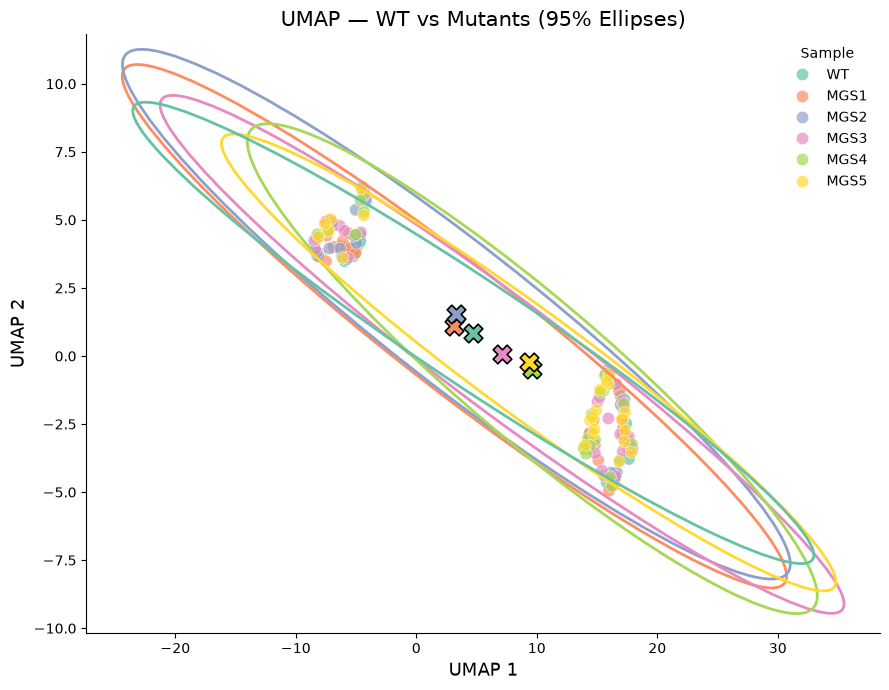

In [12]:
# Prepare data
plot_df = umap_df.dropna(
    subset=["UMAP1", "UMAP2", "sample"]
).copy()

# Consistent colors
samples = plot_df["sample"].unique()

palette = dict(zip(
    samples,
    sns.color_palette("Set2", n_colors=len(samples))
))

# Plot
fig, ax = plt.subplots(figsize=(9, 7))

sns.scatterplot(
    data=plot_df,
    x="UMAP1",
    y="UMAP2",
    hue="sample",
    palette=palette,
    s=80,
    alpha=0.7,
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

# Add ellipses and centroids
for group, data in plot_df.groupby("sample"):

    confidence_ellipse(
        data["UMAP1"],
        data["UMAP2"],
        ax=ax,
        confidence=0.95,
        edgecolor=palette[group]
    )

    ax.scatter(
        data["UMAP1"].mean(),
        data["UMAP2"].mean(),
        marker="X",
        s=180,
        color=palette[group],
        edgecolor="black",
        linewidth=1.2,
        zorder=5
    )

ax.set_xlabel("UMAP 1", fontsize=13)
ax.set_ylabel("UMAP 2", fontsize=13)
ax.set_title(
    "UMAP — WT vs Mutants (95% Ellipses)",
    fontsize=15
)

ax.legend(title="Sample", frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

### Check the amount of clusters in UMAPs

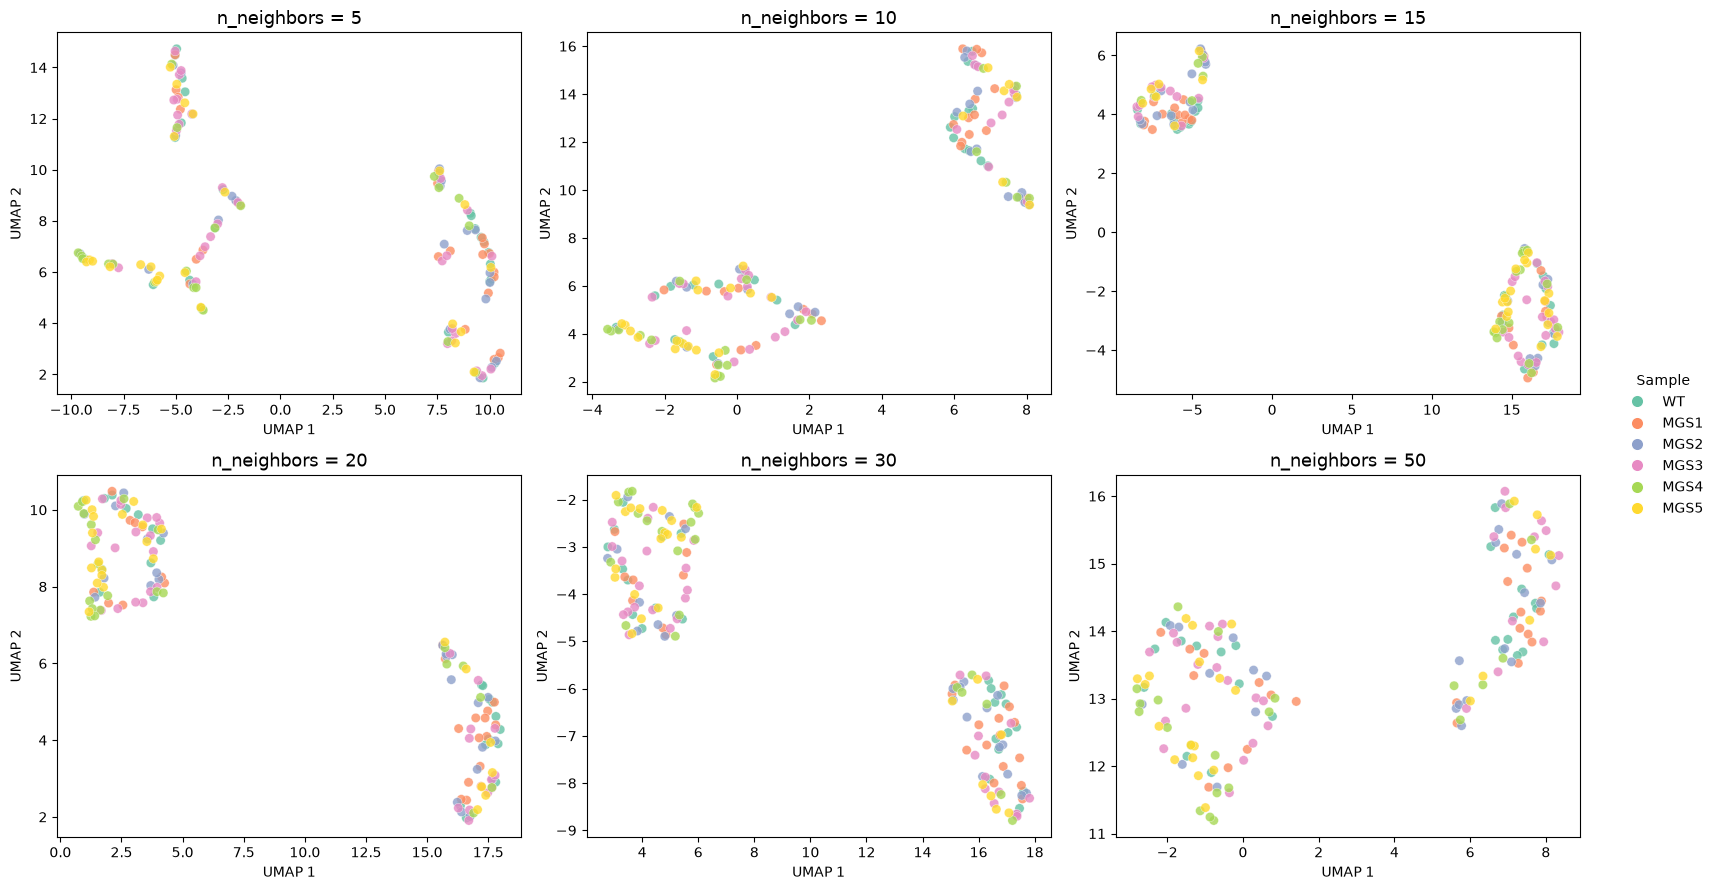

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

neighbors = [5, 10, 15, 20, 30, 50]

# Consistent colors for samples
samples = subset["sample"].unique()

palette = dict(zip(
    samples,
    sns.color_palette("Set2", len(samples))
))

for ax, n in zip(axes.flat, neighbors):

    reducer = umap.UMAP(
        n_neighbors=n,
        min_dist=0.1,
        random_state=42,
        n_jobs=1,
    )

    embedding = reducer.fit_transform(X_scaled)

    sns.scatterplot(
        x=embedding[:, 0],
        y=embedding[:, 1],
        hue=subset["sample"].to_numpy(),
        hue_order=samples,
        palette=palette,
        s=45,
        alpha=0.8,
        edgecolor="white",
        linewidth=0.3,
        legend=False,
        ax=ax
    )

    ax.set_title(f"n_neighbors = {n}", fontsize=13)
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")

# Create shared legend
from matplotlib.lines import Line2D

handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        label=sample,
        markerfacecolor=palette[sample],
        markeredgecolor="white",
        markersize=9
    )
    for sample in samples
]

fig.legend(
    handles=handles,
    title="Sample",
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    frameon=False
)

plt.tight_layout()
plt.show()

### Visualize each sample separately

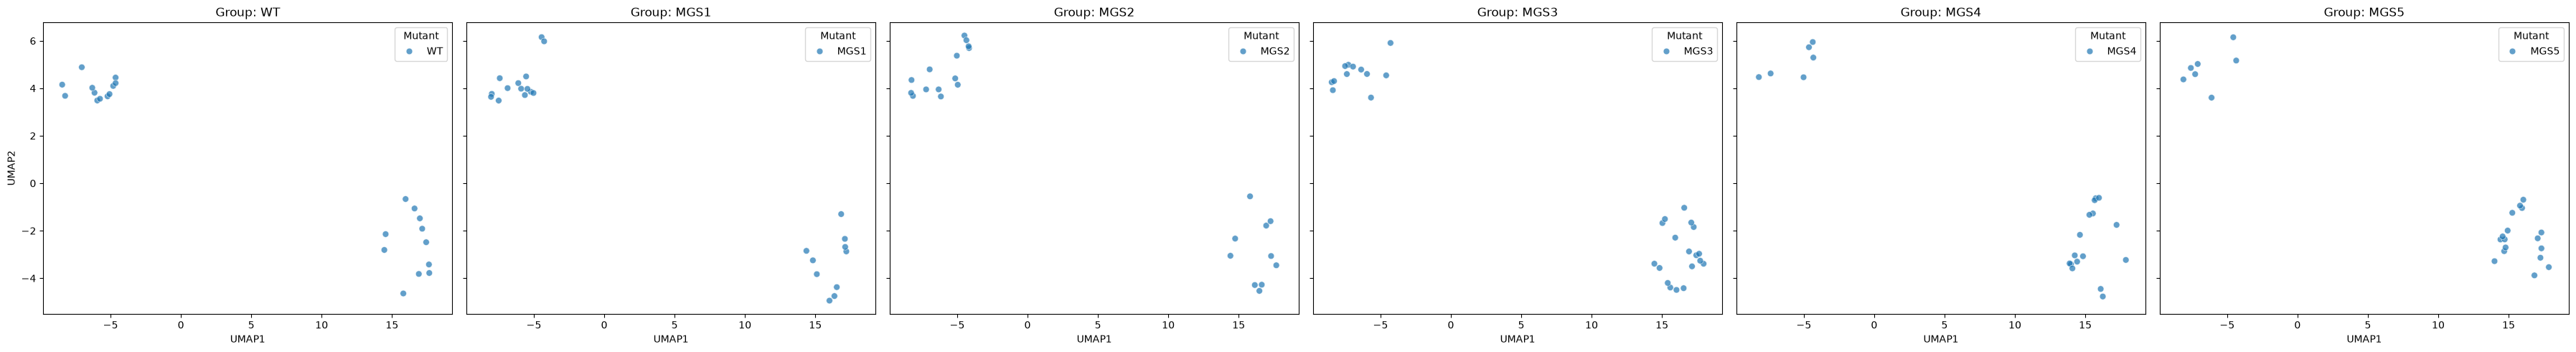

In [15]:
groups = umap_df["sample"].unique()

fig, axes = plt.subplots(
    1, len(groups),
    figsize=(6 * len(groups), 5),
    sharex=True,
    sharey=True
)

for ax, group in zip(axes, groups):
    subset = umap_df[umap_df["sample"] == group]

    sns.scatterplot(
        data=subset,
        x="UMAP1",
        y="UMAP2",
        hue="sample",
        alpha=0.7,
        s=40,
        ax=ax
    )

    ax.set_title(f"Group: {group}")
    ax.legend(title="Mutant")

plt.tight_layout()
plt.show()

In [ ]:
import math

groups = umap_df["sample"].dropna().unique()
n_groups = len(groups)

# Layout: 2 columns
ncols = min(2, n_groups)
nrows = math.ceil(n_groups / ncols)

# Consistent colors
palette = dict(zip(
    groups,
    sns.color_palette("Set2", n_groups)
))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(9 * ncols, 7 * nrows),
    sharex=True,
    sharey=True,
    squeeze=False
)

axes = axes.flatten()

# Consistent axis limits with padding
x_min, x_max = umap_df["UMAP1"].min(), umap_df["UMAP1"].max()
y_min, y_max = umap_df["UMAP2"].min(), umap_df["UMAP2"].max()

x_pad = (x_max - x_min) * 0.05
y_pad = (y_max - y_min) * 0.05

for ax, group in zip(axes, groups):

    subset = umap_df[umap_df["sample"] == group]

    sns.scatterplot(
        data=subset,
        x="UMAP1",
        y="UMAP2",
        color=palette[group],
        alpha=0.85,
        s=100,
        edgecolor="white",
        linewidth=0.5,
        ax=ax
    )

    ax.set_title(
        f"{group} (n={len(subset)})",
        fontsize=17,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("UMAP 1", fontsize=14)
    ax.set_ylabel("UMAP 2", fontsize=14)

    ax.set_xlim(x_min - x_pad, x_max + x_pad)
    ax.set_ylim(y_min - y_pad, y_max + y_pad)

    ax.tick_params(labelsize=12)
    ax.grid(alpha=0.15)

# Remove unused panels
for ax in axes[n_groups:]:
    ax.remove()

plt.tight_layout(pad=3)
plt.show()

NameError: name 'math' is not defined

### KMeans

In [16]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

umap_df["cluster"] = kmeans.fit_predict(
    umap_df[["UMAP1", "UMAP2"]]
)

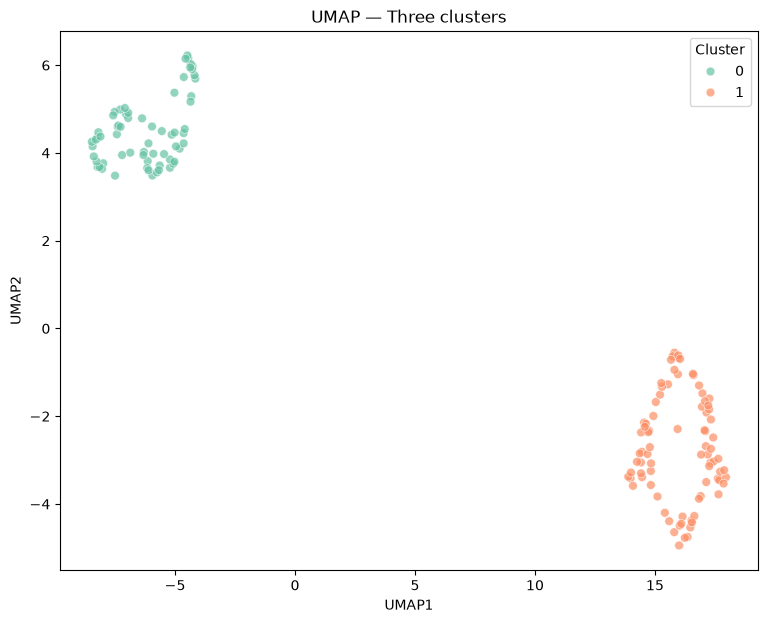

In [17]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="cluster",
    palette="Set2",
    s=40,
    alpha=0.7
)

plt.title("UMAP — Three clusters")
plt.legend(title="Cluster")
plt.show()

In [ ]:
# Select features and groups
data = df[features + ["sample"]].dropna().copy()

X = data[features]
groups = data["sample"].to_numpy()

# Standardize features
X_scaled = StandardScaler().fit_transform(X)

# Euclidean distance matrix
distances = squareform(
    pdist(X_scaled, metric="euclidean")
)

dm = DistanceMatrix(distances)

# PERMANOVA
permanova_result = permanova(
    dm,
    grouping=groups,
    permutations=9999,
    seed=42
)

# PERMDISP
permdisp_result = permdisp(
    dm,
    grouping=groups,
    test="centroid",
    permutations=9999,
    seed=42
)

# Calculate R²
F = permanova_result["test statistic"]
n = len(groups)
k = len(np.unique(groups))

R2 = (F * (k - 1)) / (F * (k - 1) + (n - k))

# Results dataframe
results_df = pd.DataFrame({
    "Test": ["PERMANOVA", "PERMDISP"],
    "Statistic": [
        permanova_result["test statistic"],
        permdisp_result["test statistic"]
    ],
    "p_value": [
        permanova_result["p-value"],
        permdisp_result["p-value"]
    ],
    "R2": [R2, np.nan],
    "n": [n, n],
    "groups": [k, k]
})

display(results_df.round(4))

In [ ]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

for cluster, ax in zip(sorted(umap_df["cluster"].unique()), axes):

    subset = umap_df[umap_df["cluster"] == cluster]

    sns.scatterplot(
        data=subset,
        x="UMAP1",
        y="UMAP2",
        hue="sample",
        palette="tab10",
        alpha=0.7,
        s=35,
        ax=ax
    )

    ax.set_title(f"Cluster {cluster}")

plt.tight_layout()
plt.show()

In [ ]:
counts = pd.crosstab(
    umap_df["sample"],
    umap_df["cluster"]
)

proportions = counts.div(
    counts.sum(axis=1),
    axis=0
) * 100

print(proportions.round(2))

proportions.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    colormap="Set2"
)

plt.ylabel("Cells (%)")
plt.xlabel("Sample")
plt.title("Cluster distribution by sample")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [ ]:
df = df.copy()
df["cluster"] = umap_df["cluster"].to_numpy()

In [ ]:
results = []

for cluster, subset in df.groupby("cluster"):

    subset = subset.dropna(subset=features)

    if subset["sample"].nunique() < 2:
        continue

    X = StandardScaler().fit_transform(subset[features])

    distances = squareform(
        pdist(X, metric="euclidean")
    )

    dm = DistanceMatrix(
        distances,
        ids=[str(i) for i in range(len(subset))]
    )

    result = permanova(
        dm,
        grouping=subset["sample"].to_numpy(),
        permutations=9999
    )

    results.append({
        "cluster": cluster,
        "F": result["test statistic"],
        "p_value": result["p-value"],
        "n": len(subset)
    })

results_df = pd.DataFrame(results)
print(results_df)

In [ ]:
results = []

for feature in features:
    for axis in ["UMAP1", "UMAP2"]:
        rho, p = spearmanr(
            df[feature],
            umap_df[axis],
            nan_policy="omit"
        )

        results.append({
            "Feature": feature,
            "Axis": axis,
            "Correlation": rho,
            "p_value": p
        })

corr_df = pd.DataFrame(results)

corr_matrix = corr_df.pivot(
    index="Feature",
    columns="Axis",
    values="Correlation"
)

print(corr_matrix)

In [ ]:
plt.figure(figsize=(7, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Feature correlations with UMAP axes")
plt.tight_layout()
plt.show()

In [ ]:
# Settings
cluster_id = 2
reference = "WT"
n_permutations = 9999

# Select cluster 2
df_cluster = df[df["cluster"] == cluster_id].copy()

# Remove rows with missing feature values
df_cluster = df_cluster.dropna(subset=features + ["sample"])

# Standardize features once for the entire cluster
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster[features])

# Store standardized features
scaled_df = pd.DataFrame(
    X_scaled,
    index=df_cluster.index,
    columns=features
)

# Identify mutants
mutants = [
    sample for sample in df_cluster["sample"].unique()
    if sample != reference
]

results = []

for mutant in mutants:

    # Select WT and current mutant
    subset = df_cluster[
        df_cluster["sample"].isin([reference, mutant])
    ].copy()

    if subset["sample"].nunique() < 2:
        continue

    # Standardized features
    X = scaled_df.loc[subset.index].to_numpy()

    # Euclidean distance matrix
    distances = squareform(
        pdist(X, metric="euclidean")
    )

    dm = DistanceMatrix(
        distances,
        ids=[str(i) for i in range(len(subset))]
    )

    grouping = subset["sample"].to_numpy()

    # PERMANOVA
    perm = permanova(
        dm,
        grouping=grouping,
        permutations=n_permutations,
        seed=42
    )

    # PERMDISP
    disp = permdisp(
        dm,
        grouping=grouping,
        permutations=n_permutations,
        seed=42
    )

    # PERMANOVA R²
    F = perm["test statistic"]
    n = len(subset)
    k = 2

    R2 = (F * (k - 1)) / (
        F * (k - 1) + (n - k)
    )

    results.append({
        "Comparison": f"{reference} vs {mutant}",
        "n_WT": (subset["sample"] == reference).sum(),
        "n_mutant": (subset["sample"] == mutant).sum(),
        "PERMANOVA_F": F,
        "PERMANOVA_p": perm["p-value"],
        "R2": R2,
        "PERMDISP_F": disp["test statistic"],
        "PERMDISP_p": disp["p-value"]
    })

# Results
results_df = pd.DataFrame(results)

# FDR correction
if not results_df.empty:
    results_df["PERMANOVA_p_adj"] = multipletests(
        results_df["PERMANOVA_p"],
        method="fdr_bh"
    )[1]

    results_df["PERMDISP_p_adj"] = multipletests(
        results_df["PERMDISP_p"],
        method="fdr_bh"
    )[1]

print(results_df.round(4))

In [ ]:
from scipy.stats import ttest_ind

results = []

for feature in features:
    wt = df.loc[df["sample"] == "WT", feature].dropna()
    mgs3 = df.loc[df["sample"] == "MGS3", feature].dropna()

    # Cohen's d
    pooled_sd = np.sqrt(
        ((len(wt)-1)*wt.var(ddof=1) +
         (len(mgs3)-1)*mgs3.var(ddof=1)) /
        (len(wt)+len(mgs3)-2)
    )

    d = (mgs3.mean() - wt.mean()) / pooled_sd if pooled_sd > 0 else np.nan

    results.append({
        "Feature": feature,
        "WT_mean": wt.mean(),
        "MGS3_mean": mgs3.mean(),
        "Cohens_d": d,
        "p_value": ttest_ind(wt, mgs3, equal_var=False).pvalue
    })

feature_results = pd.DataFrame(results)

display(
    feature_results.sort_values(
        "Cohens_d",
        key=abs,
        ascending=False
    )
)